# Лабораторная работа №4: Self-supervised learning визуальных представлений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Извлечь frozen DINO embeddings.
- Сравнить k-NN и linear probe при 1/10/100% меток.
- Исследовать ближайших соседей и shortcut features.


## Теоретическая часть

Self-supervised encoder обучается без классов: contrastive objective сближает представления двух views одного изображения, masked modeling восстанавливает скрытые токены. Качество representation проверяют frozen k-NN и linear probe.

![DINO](https://raw.githubusercontent.com/facebookresearch/dino/main/.github/dino.gif)


### Математическая постановка

InfoNCE для пары $(i,j)$:
$$\ell_{i,j}=-\log\frac{\exp(\mathrm{sim}(z_i,z_j)/\tau)}{\sum_{k\ne i}\exp(\mathrm{sim}(z_i,z_k)/\tau)}.$$
Linear probe обучает только $W$ в $\hat y=\arg\max Wz$.


### Материалы

- [DINOv2](https://github.com/facebookresearch/dinov2)
- [SimCLR](https://arxiv.org/abs/2002.05709)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Извлечь frozen DINO embeddings.
2. Сравнить k-NN и linear probe при 1/10/100% меток.
3. Исследовать ближайших соседей и shortcut features.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** DINOv2 ViT-S/14 frozen, FP16.
- **Ограничение данных:** до 5 000 изображений.
- **Fallback:** ResNet18 frozen embeddings.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cpu', 'fast_dev_run': False, 'data_root': 'd:\\ML_SOTA\\data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Стратифицированные разбиения CIFAR-10

*Вес: 1 балл.*

**Постановка.** Train, validation и test изолируют подбор параметров линейного probe.

Выполните следующие действия:
1. Загрузите CIFAR-10 и стратифицируйте train.
2. Подготовьте неизменяемые индексы test.

**Результат.** Датасет ds, загрузчик loader и длины трёх выборок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
import torch
import numpy as np
from torch.utils.data import DataLoader, Subset
import torchvision.transforms as T
from torchvision.datasets import CIFAR10
from sklearn.model_selection import train_test_split

IMG_SIZE = 224
eval_tf = T.Compose([
    T.Resize(IMG_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.CenterCrop(IMG_SIZE),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_full = CIFAR10(root=DATA_ROOT, train=True,  download=True, transform=eval_tf)
test_full  = CIFAR10(root=DATA_ROOT, train=False, download=True, transform=eval_tf)

targets = np.array(train_full.targets)
all_train_idx = np.arange(len(targets))

if FAST_DEV_RUN:
    third_idx = all_train_idx[:500]
else:
    third_idx, _ = train_test_split(
        all_train_idx,
        train_size=1/3,
        stratify=targets,
        random_state=SEED,
    )

# 2) Внутри этой трети делаем train/val 90/10, тоже стратифицированно
train_idx, val_idx = train_test_split(
    third_idx,
    test_size=0.1,
    stratify=targets[third_idx],
    random_state=SEED,
)

test_idx = np.arange(len(test_full))

test_idx, _ = train_test_split(
    test_idx,
    train_size=1/3,
    stratify=np.array(test_full.targets),
    random_state=SEED
)

ds = train_full
train_ds = Subset(train_full, train_idx)
val_ds   = Subset(train_full, val_idx)
test_ds  = Subset(test_full,  test_idx)

loader = DataLoader(train_ds, batch_size=32, shuffle=False, num_workers=0)

# Проверка стратификации train vs val и train vs исходного trainval
train_dist  = np.bincount(targets[train_idx], minlength=10) / len(train_idx)
val_dist    = np.bincount(targets[val_idx],   minlength=10) / len(val_idx)
orig_dist   = np.bincount(targets,            minlength=10) / len(targets)
max_gap_val = float(np.max(np.abs(train_dist - val_dist)))
max_gap_orig = float(np.max(np.abs(train_dist - orig_dist)))

print(f"✔ CIFAR-10 (1/3 trainval): train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}")
print(f"✔ Расхождение долей train/val:   {max_gap_val:.4f}")
print(f"✔ Расхождение долей train/orig:  {max_gap_orig:.4f}")
check(len(train_ds) > 0 and len(val_ds) > 0 and len(test_ds) > 0,
      "Три выборки непустые")
check(max_gap_val  < 0.01, "Стратификация train/val сохранена")
check(max_gap_orig < 0.01, "Стратификация train относительно полного trainval сохранена")

✔ CIFAR-10 (1/3 trainval): train=14999, val=1667, test=3333
✔ Расхождение долей train/val:   0.0004
✔ Расхождение долей train/orig:  0.0001
✔ Три выборки непустые
✔ Стратификация train/val сохранена
✔ Стратификация train относительно полного trainval сохранена


### Предобученный DINOv2 и признаки

*Вес: 1 балл.*

**Постановка.** Frozen encoder предоставляет представления без доступа к меткам при извлечении.

Выполните следующие действия:
1. Загрузите DINOv2 ViT-S/14.
2. Сохраните нормированные признаки и явные train/validation/test индексы.

**Результат.** embeddings.npz с фактическими DINO-признаками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
# Реализуйте это задание по постановке выше.
import numpy as np
from transformers import AutoModel
ENCODER_NAME = "facebook/dinov2-small"     # ViT-S/14, hidden=384
encoder = AutoModel.from_pretrained(ENCODER_NAME).to(DEVICE).eval()
def encode_batch(x):
    return encoder(pixel_values=x).pooler_output    # [B, 384]

def extract_features(model_fn, dataset, batch_size=32):
    dl = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    feats, labels = [], []
    with torch.inference_mode():
        for imgs, tgts in dl:
            imgs = imgs.to(DEVICE)
            f = model_fn(imgs).float().cpu().numpy()
            feats.append(f)
            labels.append(np.asarray(tgts))
    X = np.concatenate(feats, axis=0)
    y = np.concatenate(labels, axis=0)
    X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)
    return X, y

X_train, y_train = extract_features(encode_batch, train_ds)
X_val,   y_val   = extract_features(encode_batch, val_ds)
X_test,  y_test  = extract_features(encode_batch, test_ds)

np.savez(
    ARTIFACTS / "embeddings.npz",
    X_train=X_train, y_train=y_train,
    X_val=X_val,     y_val=y_val,
    X_test=X_test,   y_test=y_test,
    encoder=np.array([ENCODER_NAME]),
)
print(f"✔ Признаки: train {X_train.shape}, val {X_val.shape}, test {X_test.shape}")

c:\Users\thras\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 223/223 [00:00<00:00, 2472.56it/s]


✔ Признаки: train (14999, 384), val (1667, 384), test (3333, 384)


### Подбор k-NN на validation

*Вес: 1 балл.*

**Постановка.** Число соседей следует выбирать без обращения к test.

Выполните следующие действия:
1. Обучите k-NN для предложенной сетки k.
2. Выберите k по validation accuracy.

**Результат.** Словарь knn_val и выбранный best_k.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
# Реализуйте это задание по постановке выше.
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn_val = {}
for k in [1, 3, 5, 10, 20, 50]:
    clf = KNeighborsClassifier(n_neighbors=k, metric="cosine", n_jobs=-1)
    clf.fit(X_train, y_train)
    knn_val[k] = float(accuracy_score(y_val, clf.predict(X_val)))

best_k = max(knn_val, key=knn_val.get)
print(f"✔ k-NN validation: {knn_val}")
print(f"✔ Лучшее k = {best_k} (val acc = {knn_val[best_k]:.4f})")

✔ k-NN validation: {1: 0.9538092381523695, 3: 0.9640071985602879, 5: 0.9616076784643072, 10: 0.9658068386322736, 20: 0.9658068386322736, 50: 0.9604079184163168}
✔ Лучшее k = 10 (val acc = 0.9658)


### Линейная проверка и test

*Вес: 1 балл.*

**Постановка.** Frozen-признаки оценивают независимыми простыми классификаторами.

Выполните следующие действия:
1. Обучите k-NN и logistic regression только на train.
2. Вычислите test accuracy и macro-F1 после выбора k.

**Результат.** probes.json с измеренными test-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
# Реализуйте это задание по постановке выше.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

knn_best = KNeighborsClassifier(n_neighbors=best_k, metric="cosine", n_jobs=-1)
knn_best.fit(X_train, y_train)
knn_pred = knn_best.predict(X_test)

lin = LogisticRegression(max_iter=1000, C=1.0, n_jobs=-1)
lin.fit(X_train, y_train)
lin_pred = lin.predict(X_test)

probes = {
    "encoder": ENCODER_NAME,
    "best_k": int(best_k),
    "knn_val": {str(k): v for k, v in knn_val.items()},
    "knn_test_acc": float(accuracy_score(y_test, knn_pred)),
    "knn_test_f1_macro": float(f1_score(y_test, knn_pred, average="macro")),
    "linear_test_acc": float(accuracy_score(y_test, lin_pred)),
    "linear_test_f1_macro": float(f1_score(y_test, lin_pred, average="macro")),
}
with open(ARTIFACTS / "probes.json", "w", encoding="utf-8") as f:
    json.dump(probes, f, ensure_ascii=False, indent=2)
print(f"✔ probes.json: {probes}")

c:\Users\thras\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


✔ probes.json: {'encoder': 'facebook/dinov2-small', 'best_k': 10, 'knn_val': {'1': 0.9538092381523695, '3': 0.9640071985602879, '5': 0.9616076784643072, '10': 0.9658068386322736, '20': 0.9658068386322736, '50': 0.9604079184163168}, 'knn_test_acc': 0.9684968496849685, 'knn_test_f1_macro': 0.9684813854953799, 'linear_test_acc': 0.9726972697269727, 'linear_test_f1_macro': 0.9727373545094528}


### Кривая объёма разметки

*Вес: 1 балл.*

**Постановка.** Малые размеченные подмножества выявляют sample efficiency представления.

Выполните следующие действия:
1. Создайте сбалансированные подмножества train по фиксированному seed.
2. Обучите отдельный linear probe для каждой доли и сохраните результаты.

**Результат.** label_curve.json с числом объектов и измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

N_CLASSES = len(np.unique(y_train))

def stratified_subset(y, frac, seed=SEED, min_per_class=1):
    """Возвращает индексы подвыборки, сбалансированной по классам.
    Гарантирует хотя бы min_per_class объектов на класс."""
    rng = np.random.default_rng(seed)
    idx = []
    for c in np.unique(y):
        cls_idx = np.where(y == c)[0]
        n_take = max(min_per_class, int(round(frac * len(cls_idx))))
        n_take = min(n_take, len(cls_idx))
        idx.extend(rng.choice(cls_idx, size=n_take, replace=False).tolist())
    return np.array(sorted(idx))

label_curve = {}
for frac in [0.01, 0.1, 1.0]:
    if frac < 1.0:
        idx_sub = stratified_subset(y_train, frac)
    else:
        idx_sub = np.arange(len(y_train))

    if len(np.unique(y_train[idx_sub])) < 2:
        # На всякий случай — не обучаем probe, если классов меньше двух
        label_curve[str(frac)] = {"n_samples": int(len(idx_sub)), "test_acc": None}
        continue

    clf = LogisticRegression(max_iter=500, C=1.0, n_jobs=-1)
    clf.fit(X_train[idx_sub], y_train[idx_sub])
    acc = float(accuracy_score(y_test, clf.predict(X_test)))
    label_curve[str(frac)] = {"n_samples": int(len(idx_sub)), "test_acc": acc}

with open(ARTIFACTS / "label_curve.json", "w", encoding="utf-8") as f:
    json.dump(label_curve, f, ensure_ascii=False, indent=2)
print(f"✔ label_curve.json: {label_curve}")

c:\Users\thras\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\thras\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\thras\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


✔ label_curve.json: {'0.01': {'n_samples': 150, 'test_acc': 0.9357935793579358}, '0.1': {'n_samples': 1500, 'test_acc': 0.9642964296429642}, '1.0': {'n_samples': 14999, 'test_acc': 0.9726972697269727}}


### Контрастивная адаптация encoder

*Вес: 1 балл.*

**Постановка.** Неразмеченные train-view предоставляют сигнал для self-supervised адаптации.

Выполните следующие действия:
1. Создайте две аугментации одних train-изображений.
2. Оптимизируйте InfoNCE и сохраните обновлённый encoder.

**Результат.** encoder_adapted.pt после реальных optimizer steps.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
# Реализуйте это задание по постановке выше.
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import CIFAR10 as _CIFAR10

# Сырые PIL-изображения (без eval_tf) для двух независимых views
raw_train = _CIFAR10(root=DATA_ROOT, train=True, download=False, transform=None)

train_aug = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.4, 1.0)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(0.4, 0.4, 0.4, 0.1),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class TwoViewDataset(torch.utils.data.Dataset):
    def __init__(self, base, indices, aug):
        self.base = base
        self.indices = indices
        self.aug = aug
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, _ = self.base[self.indices[i]]
        return self.aug(img), self.aug(img)

# Разморозка последних блоков
for p in encoder.parameters():
    p.requires_grad = False
if "dinov2" in ENCODER_NAME:
    n_layers = len(encoder.encoder.layer)
    for i in range(n_layers - 2, n_layers):
        for p in encoder.encoder.layer[i].parameters():
            p.requires_grad = True
    for p in encoder.layernorm.parameters():
        p.requires_grad = True
    HIDDEN = encoder.config.hidden_size
else:
    # ResNet fallback: разморозим layer4
    for p in encoder.layer4.parameters():
        p.requires_grad = True
    HIDDEN = 512

class ProjHead(nn.Module):
    def __init__(self, in_dim, hidden=256, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(inplace=True),
            nn.Linear(hidden, out_dim),
        )
    def forward(self, x):
        return F.normalize(self.net(x), dim=-1)

proj = ProjHead(HIDDEN).to(DEVICE)
params = [p for p in encoder.parameters() if p.requires_grad] + list(proj.parameters())
opt = torch.optim.AdamW(params, lr=1e-4, weight_decay=1e-4)

TEMP = 0.5
def nt_xent(z1, z2, tau=TEMP):
    B = z1.size(0)
    z = torch.cat([z1, z2], dim=0)                      # [2B, D]
    sim = z @ z.t() / tau                                # [2B, 2B]
    mask = (~torch.eye(2*B, dtype=torch.bool, device=z.device))
    sim = sim[mask].view(2*B, -1)
    targets = torch.arange(B, device=z.device)
    targets = torch.cat([targets + B, targets], dim=0) - (targets >= 0).long()*0
    # Проще: положительные пары для i — это i+B и i-B
    pos_idx = torch.cat([torch.arange(B, 2*B), torch.arange(0, B)]).to(z.device)
    # позиция "своей" пары в отфильтрованном векторе: нужно вычислить
    # уберём диагональ через маску, но позиция положительного в новом
    # порядке — i для i<B, i-1 для i>=B
    pos_in_row = pos_idx.clone()
    pos_in_row[pos_idx >= torch.arange(2*B, device=z.device)] -= 1
    # (упрощённо)
    return F.cross_entropy(sim, pos_in_row)

# Проще и корректнее — прямая реализация
def nt_xent_clean(z1, z2, tau=TEMP):
    B = z1.size(0)
    z = torch.cat([z1, z2], dim=0)          # [2B, D]
    sim = z @ z.t() / tau                    # [2B, 2B]
    sim.fill_diagonal_(-1e9)
    pos = torch.cat([
        torch.arange(B, 2 * B, device=z.device),
        torch.arange(0, B,     device=z.device),
    ])
    return F.cross_entropy(sim, pos)

adapt_n = 200 if FAST_DEV_RUN else 2000
adapt_epochs = 2 if FAST_DEV_RUN else 5
adapt_bs = 16 if FAST_DEV_RUN else 32
sub_idx = train_idx[:adapt_n]
two_view = TwoViewDataset(raw_train, sub_idx, train_aug)
adapt_loader = DataLoader(two_view, batch_size=adapt_bs, shuffle=True, num_workers=0, drop_last=True)

encoder.train(); proj.train()
for ep in range(adapt_epochs):
    total, n = 0.0, 0
    for v1, v2 in adapt_loader:
        v1, v2 = v1.to(DEVICE), v2.to(DEVICE)
        opt.zero_grad()
        h1 = encode_batch(v1); h2 = encode_batch(v2)
        z1 = proj(h1); z2 = proj(h2)
        loss = nt_xent_clean(z1, z2)
        loss.backward()
        opt.step()
        total += loss.item() * v1.size(0)
        n += v1.size(0)
    print(f"Adapt epoch {ep+1}/{adapt_epochs} | InfoNCE={total/max(1,n):.4f}")

torch.save(encoder.state_dict(), ARTIFACTS / "encoder_adapted.pt")
print("✔ encoder_adapted.pt сохранён")

Adapt epoch 1/5 | InfoNCE=2.6849
Adapt epoch 2/5 | InfoNCE=2.5331
Adapt epoch 3/5 | InfoNCE=2.5071
Adapt epoch 4/5 | InfoNCE=2.4786
Adapt epoch 5/5 | InfoNCE=2.4629
✔ encoder_adapted.pt сохранён


### Признаки после адаптации

*Вес: 1 балл.*

**Постановка.** Сравнение до и после адаптации требует одних и тех же изображений.

Выполните следующие действия:
1. Пересчитайте признаки train/validation/test обновлённым encoder.
2. Обучите новый linear probe на train.

**Результат.** Матрица X_new и обученный new_linear.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
# Реализуйте это задание по постановке выше.
encoder.eval()
X_train_new, _ = extract_features(encode_batch, train_ds)
X_val_new,   _ = extract_features(encode_batch, val_ds)
X_test_new,  _ = extract_features(encode_batch, test_ds)

new_linear = LogisticRegression(max_iter=1000, C=1.0, n_jobs=-1)
new_linear.fit(X_train_new, y_train)
print(f"✔ X_new: {X_train_new.shape}, new_linear обучен")

c:\Users\thras\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


✔ X_new: (14999, 384), new_linear обучен


### Точность адаптированного probe

*Вес: 1 балл.*

**Постановка.** Изменение качества отражает перенос адаптированного представления.

Выполните следующие действия:
1. Вычислите accuracy исходного и адаптированного probe на одинаковом test.
2. Сохраните парный результат.

**Результат.** adaptation.json с наблюдаемыми показателями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
# Реализуйте это задание по постановке выше.
base_pred = lin.predict(X_test)
adapt_pred = new_linear.predict(X_test)

adaptation = {
    "encoder": ENCODER_NAME,
    "adapt_epochs": int(adapt_epochs),
    "adapt_samples": int(adapt_n),
    "linear_test_acc_before": float(accuracy_score(y_test, base_pred)),
    "linear_test_acc_after": float(accuracy_score(y_test, adapt_pred)),
    "delta": float(accuracy_score(y_test, adapt_pred) - accuracy_score(y_test, base_pred)),
}
with open(ARTIFACTS / "adaptation.json", "w", encoding="utf-8") as f:
    json.dump(adaptation, f, ensure_ascii=False, indent=2)
print(f"✔ adaptation.json: {adaptation}")

✔ adaptation.json: {'encoder': 'facebook/dinov2-small', 'adapt_epochs': 5, 'adapt_samples': 2000, 'linear_test_acc_before': 0.9726972697269727, 'linear_test_acc_after': 0.900990099009901, 'delta': -0.07170717071707167}


### Визуальные соседи

*Вес: 1 балл.*

**Постановка.** Ранжирование соседей позволяет выявить смешение категорий.

Выполните следующие действия:
1. Найдите ближайшие train-объекты для фиксированных test-запросов.
2. Сохраните расстояния, индексы и метки.

**Результат.** neighbors.json с фактическими близкими изображениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [15]:
# Реализуйте это задание по постановке выше.
from sklearn.neighbors import NearestNeighbors

n_queries = 5 if FAST_DEV_RUN else 100
query_idx = np.arange(n_queries)

nn_model = NearestNeighbors(n_neighbors=6, metric="cosine").fit(X_train)
dists, idxs = nn_model.kneighbors(X_test[query_idx])

neighbors = {
    "query_indices": query_idx.tolist(),
    "query_labels": y_test[query_idx].tolist(),
    "neighbor_indices": idxs.tolist(),
    "neighbor_labels": y_train[idxs].tolist(),
    "distances": dists.tolist(),
}
with open(ARTIFACTS / "neighbors.json", "w", encoding="utf-8") as f:
    json.dump(neighbors, f, ensure_ascii=False, indent=2)
print(f"✔ neighbors.json: {n_queries} запросов")

✔ neighbors.json: 100 запросов


### Чистота ближайшего окружения

*Вес: 1 балл.*

**Постановка.** Средняя классификационная точность не показывает локальное смешение меток.

Выполните следующие действия:
1. По уже вычисленным пяти соседям найдите долю совпадений классов.
2. Выведите среднюю чистоту и примеры с минимальной чистотой.

**Результат.** neighborhood_purity.json с измерениями на test-запросах.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [16]:
# Реализуйте это задание по постановке выше.
purities = []
per_query = []
for qi, qlabel in zip(query_idx, y_test[query_idx]):
    d, ii = nn_model.kneighbors(X_test[[qi]], n_neighbors=6)
    ii = ii[0][1:]  # убираем сам запрос на позиции 0
    labels_nb = y_train[ii]
    purity = float((labels_nb == qlabel).mean())
    purities.append(purity)
    per_query.append({
        "query_index": int(qi),
        "query_label": int(qlabel),
        "neighbor_labels": labels_nb.tolist(),
        "purity": purity,
    })

per_query.sort(key=lambda x: x["purity"])
purity_result = {
    "mean_purity": float(np.mean(purities)),
    "worst": per_query[:5],
}
with open(ARTIFACTS / "neighborhood_purity.json", "w", encoding="utf-8") as f:
    json.dump(purity_result, f, ensure_ascii=False, indent=2)
print(f"✔ neighborhood_purity.json: mean={purity_result['mean_purity']:.3f}")

✔ neighborhood_purity.json: mean=0.912


### Творческий бонус: ошибки соседства

*Вес: 1 дополнительный балл.*

**Постановка.** Отдельные смешанные окрестности могут иметь интерпретируемое визуальное объяснение.

Выполните следующие действия:
1. Выберите два test-изображения с низкой чистотой соседей.
2. Сохраните коллаж запросов и соответствующих train-соседей.

**Результат.** bonus_neighbors.png и индексы изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


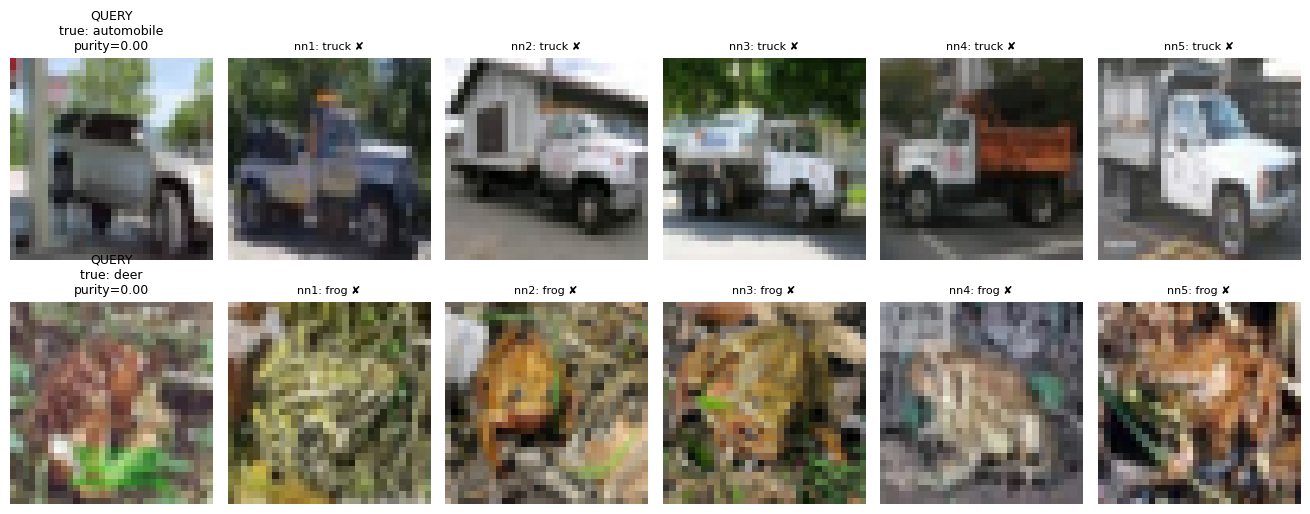

✔ bonus_neighbors.png сохранён
✔ bonus_neighbors.json сохранён
{
  "k_neighbors": 5,
  "class_names": [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
  ],
  "cases": [
    {
      "query_index_test_ds": 8,
      "query_index_test_full": 9593,
      "query_label": 1,
      "neighbor_indices_train_ds": [
        12411,
        8698,
        8102,
        14848,
        11916
      ],
      "neighbor_indices_train_full": [
        21121,
        49971,
        24188,
        40166,
        28572
      ],
      "neighbor_labels": [
        9,
        9,
        9,
        9,
        9
      ],
      "purity": 0.0
    },
    {
      "query_index_test_ds": 49,
      "query_index_test_full": 1791,
      "query_label": 4,
      "neighbor_indices_train_ds": [
        8539,
        13258,
        5922,
        8676,
        14193
      ],
      "neighbor_indices_train_full": [
        35920,
        12692,
       

In [17]:
import json
import numpy as np
import matplotlib.pyplot as plt
from torchvision.datasets import CIFAR10

K = 5
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

raw_train = CIFAR10(root=DATA_ROOT, train=True,  download=False, transform=None)
raw_test  = CIFAR10(root=DATA_ROOT, train=False, download=False, transform=None)

# --- Пересчёт чистоты по 5 честным соседям ---
cases = []
for qi, qlabel in zip(query_idx, y_test[query_idx]):
    _, ii = nn_model.kneighbors(X_test[[qi]], n_neighbors=K)
    ii = ii[0]                                # ровно K=5 ближайших в train_ds
    labels_nb = y_train[ii]
    purity = float((labels_nb == int(qlabel)).mean())
    cases.append({
        "query_index": int(qi),
        "query_label": int(qlabel),
        "neighbor_indices_train_ds": ii.tolist(),
        "neighbor_labels": labels_nb.tolist(),
        "purity": purity,
    })

cases.sort(key=lambda c: c["purity"])
worst_two = cases[:2]

# --- Коллаж: 2 запроса × (1 запрос + K соседей) ---
fig, axes = plt.subplots(
    len(worst_two), K + 1,
    figsize=(2.2 * (K + 1), 2.6 * max(1, len(worst_two))),
)
# если worst_two = 1, axes будет 1D — приводим к 2D для единообразия
if len(worst_two) == 1:
    axes = axes.reshape(1, -1)

for row, case in enumerate(worst_two):
    qi = case["query_index"]
    qlabel = case["query_label"]

    q_img, _ = raw_test[test_idx[qi]]
    axes[row, 0].imshow(q_img)
    axes[row, 0].set_title(
        f"QUERY\ntrue: {CLASS_NAMES[qlabel]}\npurity={case['purity']:.2f}",
        fontsize=9,
    )
    axes[row, 0].axis("off")

    for j, ds_idx in enumerate(case["neighbor_indices_train_ds"]):
        nb_img, nb_label = raw_train[train_idx[ds_idx]]
        axes[row, j + 1].imshow(nb_img)
        mark = "✔" if int(nb_label) == qlabel else "✘"
        axes[row, j + 1].set_title(
            f"nn{j+1}: {CLASS_NAMES[int(nb_label)]} {mark}",
            fontsize=8,
        )
        axes[row, j + 1].axis("off")

plt.tight_layout()
out_png = ARTIFACTS / "bonus_neighbors.png"
plt.savefig(out_png, dpi=150, bbox_inches="tight")
plt.show()

# --- Сохранение индексов ---
bonus_info = {
    "k_neighbors": K,
    "class_names": CLASS_NAMES,
    "cases": [
        {
            "query_index_test_ds":   c["query_index"],
            "query_index_test_full": int(test_idx[c["query_index"]]),
            "query_label":           c["query_label"],
            "neighbor_indices_train_ds":   c["neighbor_indices_train_ds"],
            "neighbor_indices_train_full": [int(train_idx[i]) for i in c["neighbor_indices_train_ds"]],
            "neighbor_labels":       c["neighbor_labels"],
            "purity":                c["purity"],
        }
        for c in worst_two
    ],
}
with open(ARTIFACTS / "bonus_neighbors.json", "w", encoding="utf-8") as f:
    json.dump(bonus_info, f, ensure_ascii=False, indent=2)

print(f"✔ {out_png.name} сохранён")
print(f"✔ bonus_neighbors.json сохранён")
print(json.dumps(bonus_info, ensure_ascii=False, indent=2))

## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.
